# 291. Evidence per aligned position for all 19 kmerseek alphabets, Pfam seed and SCOPe40 pairs

No kmerseek in this notebook. It uses the aligned pairs of
[notebook 230](https://github.com/seanome/2024-kmerseek-analysis/blob/main/notebooks/230_hp_class_conservation_in_aligned_homologs.ipynb)
and the measure of
[notebook 273](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/hp-agreement-per-100/notebooks/273_hp_agreement_per_100_positions_pfam_seed_scope40.ipynb)
([PR 99](https://github.com/seanome/2024-kmerseek-analysis/pull/99)), for every alphabet
kmerseek has instead of only `hp_thomas_dill2` and `protein20`.

**Why.** Notebook 273 found that, in Pfam seed pairs at 20% identity or less, the H/P alphabet
`hp_thomas_dill2` keeps more evidence per aligned position than the 20 amino acids (0.103 vs
0.091 bits). Its section 4 then showed that this lead goes away when pairs are grouped on one
half of their positions and measured on the other half. Olga asked on PR 99 (2026-10-14): "Is
this true for ALL 2-letter alphabets? Can we see this for all alphabets, not just 2-letter?"

**What this decides.** Which alphabets, if any, the paper can name in the sentence "keeps more
evidence per aligned position than the 20 amino acids between distant homologs". Three
outcomes:

1. `hp_thomas_dill2` comes first among the 19 alphabets: the sentence names H/P.
2. Several reduced alphabets beat the 20 amino acids and H/P is one of them: the sentence says
   "reduced alphabets", and H/P gets no sentence of its own.
3. No alphabet beats the 20 amino acids once pairs are not picked by the positions measured:
   the paper makes no such claim for any alphabet.

**Decision rule.** Written before the grouped-on-one-half numbers were computed for alphabets
other than these two. The whole-pair numbers for all 19 alphabets had already been looked at
from notebook 230's table, so the whole-pair rule below is not a blind test.

* An alphabet "beats the 20 amino acids" in a group when the 95% interval of
  I(alphabet) / I(20 aa) is above 1. The interval comes from resampling Pfam families or the
  query domain's SCOPe fold, 2,000 times.
* The answer is outcome 1 when `hp_thomas_dill2` beats the 20 amino acids and is first in at
  least 90% of the resamples, in the Pfam group and in at least 2 of the 4 SCOPe relationships.
  It is outcome 2 when at least one alphabet beats the 20 amino acids in those groups but
  outcome 1 fails. Otherwise it is outcome 3.
* The groups that count are the ones where the pairs were not picked by the positions
  measured: pairs at 20% identity or less grouped on one half of their positions and measured
  on the other half, and pairs at all identities (no picking by identity).

**Data.**

* Pfam-A 38.2 seed alignments: 163,448 sampled pairs from 29,151 families, up to 6 pairs per
  family (`~/data/pfam/230_pfam_seed_pair_alignments.parquet`, built by
  `scripts/pfam_seed_pair_alignments.py`). Pairs with at least 50 aligned positions. Aligned
  from sequence by Pfam's curators.
* SCOPe 2.08, 40% identity set: domain pairs aligned by structure with USalign
  (`~/data/scope/230_scope40_pair_alignments.parquet`, built by
  `scripts/scope_pair_structural_alignments.py`). Pairs with at least 50 aligned positions and
  TM-score at least 0.5 on one of the two domains. Grouped by SCOPe relationship: same family;
  same superfamily, different family; same fold, different superfamily; different fold, same
  class. Only the first two are homologs by SCOPe's definition.
* The 19 alphabets are the classes in kmerseek's `src/rust/alphabets.rs`, as copied into
  `notebooks/hp_conservation_utils.py` (15) and `scripts/plot_alphabet_class_shares.py` (the
  other 4: `hsdm17`, `wass14`, `mmseqs12`, `funcgroups8`). Section 1 checks that agreement and
  chance computed here equal notebook 230's stored table for all 19, so the class tables are
  the ones notebook 230 used.

**Measure.** For one pair and one alphabet, an aligned position is a column where neither
sequence has a gap. Each residue is replaced by its class. Then:

* agreement $a$: the share of aligned positions where the two classes are the same;
* chance $c = \sum_k q_k t_k$, where $q_k$ and $t_k$ are the shares of class $k$ in the query's
  and the target's aligned residues;
* evidence per aligned position, in bits:
  $I = a \log_2 \frac{a}{c} + (1-a) \log_2 \frac{1-a}{1-c}$.

$I$ is 0 when the pair agrees no more than chance, and larger is better: it is how much one
aligned position tells a perfect aligner that the two sequences are related. A group's I is the
mean over its pairs. The ratio I(alphabet) / I(20 aa) above 1 means the alphabet keeps more
evidence per position than the 20 amino acids for those pairs.

**Grouped on one half, measured on the other.** Identity is the 20 amino acid agreement
itself, so the pairs at 20% identity or less are the pairs where the 20 amino acids happened to
agree least. Any other alphabet then looks better than the 20 amino acids. To remove this, each
pair's aligned positions are numbered and split into odd and even. The pair is put in the 20%
or less group by the identity of its even positions, and I is computed on its odd positions,
for every alphabet. Then odd and even are swapped and both are pooled, as in notebook 273
section 4a.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import hp_conservation_utils as hc
import pubfig as pf

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(60)

PFAM_ALN = Path("/Users/olga/data/pfam/230_pfam_seed_pair_alignments.parquet")
SCOPE_ALN = Path("/Users/olga/data/scope/230_scope40_pair_alignments.parquet")
PFAM_230 = Path("/Users/olga/data/pfam/230_pfam_seed_pair_class_agreement.parquet")
SCOPE_230 = Path("/Users/olga/data/scope/230_scope40_pair_class_agreement.parquet")
SCOPE_FA = Path(
    "/Users/olga/data/scope/astral-scopedom-seqres-gd-sel-gs-bib-40-2.08.fa"
)
FIG = Path("../figures")

MIN_COLS = 50  # same filter as notebooks 230 and 273
MIN_TM = 0.5  # SCOPe only, same as notebooks 230 and 273
LOW = 0.20  # "20% identity or less"
N_BOOT = 2_000
SEED = 291
P20 = "protein20"
HP = "hp_thomas_dill2"

# The four alphabets not in hp_conservation_utils, copied from
# scripts/plot_alphabet_class_shares.py (itself from kmerseek's src/rust/alphabets.rs).
# Registered in hc.TABLES for this notebook only, so other notebooks' defaults do not change.
EXTRA_ALPHABETS = {
    "hsdm17": [
        "A",
        "D",
        "KE",
        "R",
        "N",
        "T",
        "S",
        "Q",
        "Y",
        "F",
        "LIV",
        "M",
        "C",
        "W",
        "H",
        "G",
        "P",
    ],
    "wass14": [
        "WM",
        "DI",
        "P",
        "C",
        "AV",
        "K",
        "T",
        "RE",
        "G",
        "L",
        "Y",
        "SH",
        "F",
        "NQ",
    ],
    "mmseqs12": ["AST", "LM", "IV", "KR", "EQ", "ND", "FY", "C", "G", "H", "P", "W"],
    "funcgroups8": ["GVALI", "ST", "CM", "FY", "WHP", "NQ", "DE", "KR"],
}
for name, clusters in EXTRA_ALPHABETS.items():
    assert sorted("".join(clusters)) == sorted(hc.AA20), name
    hc.TABLES[name] = hc._table(clusters)
CLUSTERS = hc.ALPHABET_CLUSTERS | EXTRA_ALPHABETS
N_CLASSES = {a: len(c) for a, c in CLUSTERS.items()}
# most classes first, so the 20 amino acids are the top row of every figure
ALPHABETS = sorted(CLUSTERS, key=lambda a: (-N_CLASSES[a], a))
I_P20, I_HP = ALPHABETS.index(P20), ALPHABETS.index(HP)
TWO_CLASS = [a for a in ALPHABETS if N_CLASSES[a] == 2]
TOOLS = hc.NO_TOOL + "; class tables of the 19 alphabets"


def stamp(fig, path, **kw):
    # pubfig figures use constrained layout; hc.finish_figure calls fig.tight_layout(), which
    # replaces it and pulls the legend over the panels. Fix the constrained positions first.
    fig.canvas.draw()
    fig.set_layout_engine("none")
    fig.tight_layout = lambda *a, **k: None
    hc.finish_figure(fig, path, **kw)


print(
    f"{len(ALPHABETS)} alphabets; {len(TWO_CLASS)} with two classes: {', '.join(TWO_CLASS)}"
)

19 alphabets; 6 with two classes: hp_kyte_doolittle2, hp_lehninger2, hp_lehninger_c_nonpolar2, hp_pbotc_1st_ed2, hp_thomas_dill2, hp_thomas_dill_no_c2


## 1. Agreement, chance and evidence for every pair and every alphabet

Each pair is flattened to its aligned positions once, then agreement, chance and I are computed
for all 19 alphabets: on the whole pair, and on its odd and its even positions separately. The
whole-pair agreement and chance are checked against notebook 230's stored table. The figure
shows how many pairs are in each group used below.

In [2]:
def evidence_all(q, t, group, n_groups):
    # (agree, I) arrays of shape (alphabets, groups)
    out = [hc.grouped_evidence(q, t, group, n_groups, a) for a in ALPHABETS]
    return (
        np.stack([o[1] for o in out]),
        np.stack([o[2] for o in out]),
        np.stack([o[3] for o in out]),
    )


# ---- Pfam ----
pf_aln = pl.read_parquet(PFAM_ALN)
pq, pt, pidx, ppos, pkept = hc.aligned_codes(pf_aln, MIN_COLS)
pf_pairs = pf_aln[pkept].select("family", "query", "target", "seqid_ali")
n_pf = pf_pairs.height
pf_agree, pf_chance, pf_I = evidence_all(pq, pt, pidx, n_pf)
pf_ah, _, pf_Ih = evidence_all(pq, pt, pidx * 2 + ppos % 2, 2 * n_pf)
pf_ah, pf_Ih = pf_ah.reshape(-1, n_pf, 2), pf_Ih.reshape(-1, n_pf, 2)

# ---- SCOPe ----
fold_of = {}
for line in open(SCOPE_FA):
    if line.startswith(">"):
        f = line[1:].split()
        fold_of[f[0]] = ".".join(f[1].split(".")[:2])
sc_aln = pl.read_parquet(SCOPE_ALN).filter(pl.max_horizontal("tm_q", "tm_t") >= MIN_TM)
sq, st, sidx, spos, skept = hc.aligned_codes(sc_aln, MIN_COLS)
sc_pairs = sc_aln[skept].select("query", "target", "category", "seqid_ali")
n_sc = sc_pairs.height
sc_agree, sc_chance, sc_I = evidence_all(sq, st, sidx, n_sc)
sc_ah, _, sc_Ih = evidence_all(sq, st, sidx * 2 + spos % 2, 2 * n_sc)
sc_ah, sc_Ih = sc_ah.reshape(-1, n_sc, 2), sc_Ih.reshape(-1, n_sc, 2)
sc_fold = np.array([fold_of[q] for q in sc_pairs["query"]])
sc_cat = sc_pairs["category"].to_numpy()
pf_fam = pf_pairs["family"].to_numpy()


def check_230(pairs, keys, agree, chance, path):
    long = pl.concat(
        [
            pairs.select(keys).with_columns(
                alphabet=pl.lit(a),
                agree_here=pl.Series(agree[i]),
                chance_here=pl.Series(chance[i]),
            )
            for i, a in enumerate(ALPHABETS)
        ]
    )
    old = pl.read_parquet(path).select(*keys, "alphabet", "agree", "expected")
    j = long.join(old, on=[*keys, "alphabet"])
    return dict(
        rows_here=long.height,
        matched_to_230=j.height,
        alphabets_matched=j["alphabet"].n_unique(),
        max_abs_agree_diff=float((j["agree_here"] - j["agree"]).abs().max()),
        max_abs_chance_diff=float((j["chance_here"] - j["expected"]).abs().max()),
    )


print(
    "Agreement and chance against notebook 230's stored table (all pairs x all alphabets):"
)
print(
    pl.DataFrame(
        [
            {"data": "Pfam seed"}
            | check_230(
                pf_pairs, ["family", "query", "target"], pf_agree, pf_chance, PFAM_230
            ),
            {"data": "SCOPe40"}
            | check_230(sc_pairs, ["query", "target"], sc_agree, sc_chance, SCOPE_230),
        ]
    )
)
print(
    f"\nPfam: {n_pf:_} pairs from {pf_pairs['family'].n_unique():_} families; "
    f"SCOPe: {n_sc:_} pairs, query domains from {np.unique(sc_fold).size:_} folds"
)

Agreement and chance against notebook 230's stored table (all pairs x all alphabets):
shape: (2, 6)
┌───────────┬───────────┬────────────────┬───────────────────┬────────────────────┬─────────────────────┐
│ data      ┆ rows_here ┆ matched_to_230 ┆ alphabets_matched ┆ max_abs_agree_diff ┆ max_abs_chance_diff │
│ ---       ┆ ---       ┆ ---            ┆ ---               ┆ ---                ┆ ---                 │
│ str       ┆ i64       ┆ i64            ┆ i64               ┆ f64                ┆ f64                 │
╞═══════════╪═══════════╪════════════════╪═══════════════════╪════════════════════╪═════════════════════╡
│ Pfam seed ┆ 2821158   ┆ 2821158        ┆ 19                ┆ 0.0                ┆ 3.3307e-16          │
│ SCOPe40   ┆ 465595    ┆ 465595         ┆ 19                ┆ 0.0                ┆ 3.3307e-16          │
└───────────┴───────────┴────────────────┴───────────────────┴────────────────────┴─────────────────────┘



Pfam: 148_482 pairs from 26_645 families; SCOPe: 24_505 pairs, query domains from 773 folds


Items per group: pairs, or pair-halves for 'grouped on one half'. Clusters are Pfam families or the query domain's SCOPe fold.
shape: (15, 5)
┌───────────────────────────────────────────┬───────────────────────────────────────────────────────────────┬────────┬──────────┬─────────────────┐
│ group                                     ┆ pairs_used                                                    ┆ items  ┆ clusters ┆ dropped_for_nan │
│ ---                                       ┆ ---                                                           ┆ ---    ┆ ---      ┆ ---             │
│ str                                       ┆ str                                                           ┆ i64    ┆ i64      ┆ i64             │
╞═══════════════════════════════════════════╪═══════════════════════════════════════════════════════════════╪════════╪══════════╪═════════════════╡
│ Pfam seed                                 ┆ all identities, whole pairs                                   ┆ 148482 ┆

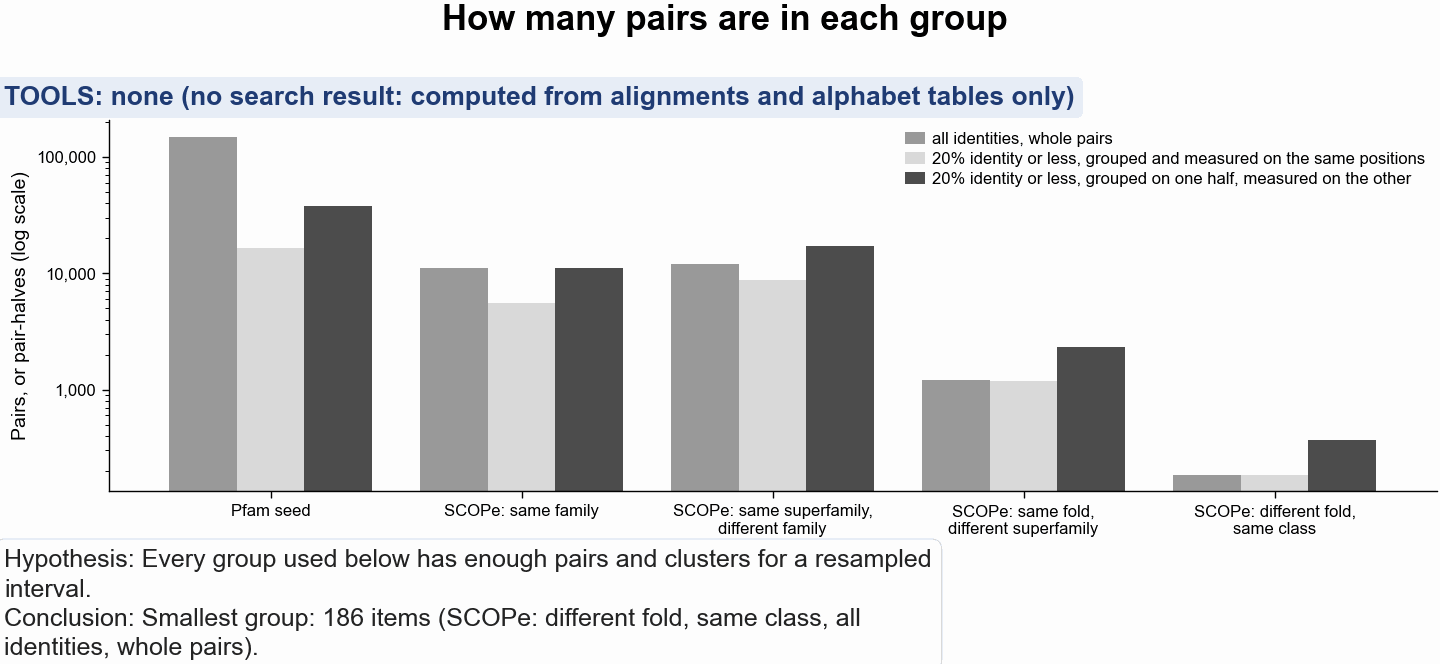

In [3]:
CAT_ORDER = [
    "same_family",
    "same_superfamily_diff_family",
    "same_fold_diff_superfamily",
    "diff_fold_same_class",
]
CAT_LABEL = {
    "same_family": "SCOPe: same family",
    "same_superfamily_diff_family": "SCOPe: same superfamily,\ndifferent family",
    "same_fold_diff_superfamily": "SCOPe: same fold,\ndifferent superfamily",
    "diff_fold_same_class": "SCOPe: different fold,\nsame class",
}
MODES = {
    "all": "all identities, whole pairs",
    "low_same": "20% identity or less, grouped and measured on the same positions",
    "low_half": "20% identity or less, grouped on one half, measured on the other",
}


def items(I, Ih, a20, ah20, clusters, subset):
    # I values (alphabets x items) and cluster labels for one group in the three modes
    out = {}
    out["all"] = (I[:, subset], clusters[subset])
    m = subset & (a20 <= LOW)
    out["low_same"] = (I[:, m], clusters[m])
    vals, cl = [], []
    for grp, meas in ((0, 1), (1, 0)):
        m = subset & (ah20[:, grp] <= LOW)
        vals.append(Ih[:, m, meas])
        cl.append(clusters[m])
    out["low_half"] = (np.concatenate(vals, 1), np.concatenate(cl))
    dropped = {}
    for k, (v, c) in out.items():
        ok = ~np.isnan(v).any(0)  # an alphabet's chance of 0 or 1 gives I = nan
        dropped[k] = int((~ok).sum())
        out[k] = (v[:, ok], c[ok])
    return out, dropped


GROUPS = {
    "Pfam seed": items(
        pf_I, pf_Ih, pf_agree[I_P20], pf_ah[I_P20], pf_fam, np.ones(n_pf, bool)
    )
}
for c in CAT_ORDER:
    GROUPS[CAT_LABEL[c]] = items(
        sc_I, sc_Ih, sc_agree[I_P20], sc_ah[I_P20], sc_fold, sc_cat == c
    )

size_rows = []
for g, (modes, dropped) in GROUPS.items():
    for k, (v, c) in modes.items():
        size_rows.append(
            dict(
                group=g.replace("\n", " "),
                pairs_used=MODES[k],
                items=v.shape[1],
                clusters=np.unique(c).size,
                dropped_for_nan=dropped[k],
            )
        )
sizes = pl.DataFrame(size_rows)
print(
    "Items per group: pairs, or pair-halves for 'grouped on one half'. Clusters are Pfam families "
    "or the query domain's SCOPe fold."
)
print(sizes)

pf.use_style()
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 55)
labels = list(GROUPS)
x = np.arange(len(labels))
w = 0.27
shade = {"all": pf.GREY, "low_same": "#d9d9d9", "low_half": "#4d4d4d"}
for j, k in enumerate(MODES):
    n = [
        sizes.filter(
            (pl.col("group") == g.replace("\n", " "))
            & (pl.col("pairs_used") == MODES[k])
        )["items"][0]
        for g in labels
    ]
    ax.bar(x + (j - 1) * w, n, w, color=shade[k], label=MODES[k])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xticks(x, labels)
ax.set_ylabel("Pairs, or pair-halves (log scale)")
ax.legend(loc="upper right", frameon=False)
pf.save(fig, FIG / "291_group_sizes_pfam_seed_scope40_print", formats=("pdf", "png"))
stamp(
    fig,
    FIG / "291_group_sizes_pfam_seed_scope40.png",
    tools=hc.NO_TOOL,
    title="How many pairs are in each group",
    hypothesis="Every group used below has enough pairs and clusters for a resampled interval.",
    conclusion=(
        f"Smallest group: {sizes['items'].min():_} items "
        f"({sizes.sort('items')['group'][0]}, {sizes.sort('items')['pairs_used'][0]})."
    ),
)

## 2. Evidence per aligned position for all 19 alphabets, as a ratio to the 20 amino acids

For each group, the mean I of each alphabet is divided by the mean I of the 20 amino acids. The
95% interval resamples Pfam families, or the query domain's SCOPe fold, 2,000 times. "First in"
is the share of resamples in which the alphabet has the highest mean I of all 19.

How to read the figure: one row per alphabet, most classes at the top. A mark right of the
dashed line keeps more evidence per position than the 20 amino acids for those pairs. Read the
diamonds first: they are the fair test, on top of each row. Filled circles (all identities) are
the second view without bias. The small grey open circles at the bottom of each row are the
biased view (pairs picked by the 20 amino acid identity of the same positions measured), drawn
only to show where notebook 273's 1.13 came from; they are not a result. Vermillion: the six
alphabets with two classes; blue: the rest.

In [4]:
rng = np.random.default_rng(SEED)


def summarise_group(v, clusters):
    u, inv = np.unique(clusters, return_inverse=True)
    S = np.stack(
        [np.bincount(inv, weights=row, minlength=u.size) for row in v]
    )  # alphabets x clusters
    cnt = np.bincount(inv, minlength=u.size).astype(float)
    mean = v.mean(1)
    ratios, first = [], np.zeros(len(ALPHABETS))
    for _ in range(N_BOOT // 200):
        W = np.stack(
            [
                np.bincount(rng.integers(0, u.size, u.size), minlength=u.size)
                for _ in range(200)
            ]
        )
        M = (W @ S.T) / (W @ cnt)[:, None]
        ratios.append(M / M[:, [I_P20]])
        first += np.bincount(M.argmax(1), minlength=len(ALPHABETS))
    R = np.concatenate(ratios)
    rank = (-mean).argsort().argsort() + 1
    return pl.DataFrame(
        dict(
            alphabet=ALPHABETS,
            classes=[N_CLASSES[a] for a in ALPHABETS],
            I_bits=mean,
            ratio_to_20aa=mean / mean[I_P20],
            lo=np.percentile(R, 2.5, 0),
            hi=np.percentile(R, 97.5, 0),
            first_in=first / N_BOOT,
            rank=rank,
        )
    )


res = []
for g, (modes, _) in GROUPS.items():
    for k, (v, c) in modes.items():
        res.append(
            summarise_group(v, c).with_columns(
                group=pl.lit(g.replace("\n", " ")), mode=pl.lit(k)
            )
        )
res = pl.concat(res)
res.write_parquet(
    Path(
        "/Users/olga/data/pfam/291_evidence_ratio_19_alphabets_pfam_seed_scope40.parquet"
    )
)

ROUND = [
    pl.col("I_bits").round(4),
    pl.col("ratio_to_20aa", "lo", "hi").round(3),
    pl.col("first_in").round(3),
]
for g in GROUPS:
    gname = g.replace("\n", " ")
    for k in ("low_half", "all"):
        print(f"\n{gname}: {MODES[k]}")
        print(
            res.filter((pl.col("group") == gname) & (pl.col("mode") == k))
            .sort("rank")
            .drop("group", "mode")
            .with_columns(ROUND)
        )


Pfam seed: 20% identity or less, grouped on one half, measured on the other
shape: (19, 8)
┌──────────────────────────┬─────────┬────────┬───────────────┬───────┬───────┬──────────┬──────┐
│ alphabet                 ┆ classes ┆ I_bits ┆ ratio_to_20aa ┆ lo    ┆ hi    ┆ first_in ┆ rank │
│ ---                      ┆ ---     ┆ ---    ┆ ---           ┆ ---   ┆ ---   ┆ ---      ┆ ---  │
│ str                      ┆ i64     ┆ f64    ┆ f64           ┆ f64   ┆ f64   ┆ f64      ┆ i64  │
╞══════════════════════════╪═════════╪════════╪═══════════════╪═══════╪═══════╪══════════╪══════╡
│ sdm12                    ┆ 12      ┆ 0.1687 ┆ 1.032         ┆ 1.027 ┆ 1.038 ┆ 1.0      ┆ 1    │
│ hsdm17                   ┆ 17      ┆ 0.1672 ┆ 1.023         ┆ 1.02  ┆ 1.027 ┆ 0.0      ┆ 2    │
│ mmseqs12                 ┆ 12      ┆ 0.1657 ┆ 1.014         ┆ 1.01  ┆ 1.019 ┆ 0.0      ┆ 3    │
│ protein20                ┆ 20      ┆ 0.1634 ┆ 1.0           ┆ 1.0   ┆ 1.0   ┆ 0.0      ┆ 4    │
│ dayhoff6                

In [5]:
# the decision rule, applied
def beats(g, k):
    t = res.filter((pl.col("group") == g) & (pl.col("mode") == k))
    return t.filter((pl.col("lo") > 1) & (pl.col("alphabet") != P20))


rule_rows = []
for g in GROUPS:
    gname = g.replace("\n", " ")
    for k in ("low_half", "all"):
        t = res.filter((pl.col("group") == gname) & (pl.col("mode") == k))
        hp = t.filter(pl.col("alphabet") == HP).row(0, named=True)
        top = t.sort("rank").row(0, named=True)
        b = beats(gname, k)
        rule_rows.append(
            dict(
                group=gname,
                pairs_used=MODES[k],
                alphabets_beating_20aa=b.height,
                two_class_beating_20aa=b.filter(pl.col("classes") == 2).height,
                first=top["alphabet"],
                first_ratio=round(top["ratio_to_20aa"], 3),
                first_in=round(top["first_in"], 3),
                hp_rank=hp["rank"],
                hp_ratio=round(hp["ratio_to_20aa"], 3),
                hp_interval=f"{hp['lo']:.3f}-{hp['hi']:.3f}",
                hp_first_in=round(hp["first_in"], 3),
                hp_outcome1=bool(hp["lo"] > 1 and hp["first_in"] >= 0.9),
            )
        )
rule = pl.DataFrame(rule_rows)
print(
    "Decision rule, per group (only rows where the pairs were not picked by the positions measured)"
)
print(rule)


def outcome(k):
    r = rule.filter(pl.col("pairs_used") == MODES[k])
    pfam = r.filter(pl.col("group") == "Pfam seed").row(0, named=True)
    sc = r.filter(pl.col("group").str.starts_with("SCOPe"))
    if pfam["hp_outcome1"] and sc["hp_outcome1"].sum() >= 2:
        return 1
    if (
        pfam["alphabets_beating_20aa"] > 0
        and (sc["alphabets_beating_20aa"] > 0).sum() >= 2
    ):
        return 2
    return 3


OUTCOME = {k: outcome(k) for k in ("low_half", "all")}
print(
    f"\nOutcome, 20% identity or less grouped on one half: {OUTCOME['low_half']}; "
    f"all identities, whole pairs: {OUTCOME['all']}"
)

Decision rule, per group (only rows where the pairs were not picked by the positions measured)
shape: (10, 12)
┌───────────────────────────────┬──────────────────────────────┬────────────────────────┬────────────────────────┬─────────────────┬─────────────┬──────────┬─────────┬──────────┬─────────────┬─────────────┬─────────────┐
│ group                         ┆ pairs_used                   ┆ alphabets_beating_20aa ┆ two_class_beating_20aa ┆ first           ┆ first_ratio ┆ first_in ┆ hp_rank ┆ hp_ratio ┆ hp_interval ┆ hp_first_in ┆ hp_outcome1 │
│ ---                           ┆ ---                          ┆ ---                    ┆ ---                    ┆ ---             ┆ ---         ┆ ---      ┆ ---     ┆ ---      ┆ ---         ┆ ---         ┆ ---         │
│ str                           ┆ str                          ┆ i64                    ┆ i64                    ┆ str             ┆ f64         ┆ f64      ┆ i64     ┆ f64      ┆ str         ┆ f64         ┆ bool        │
╞════

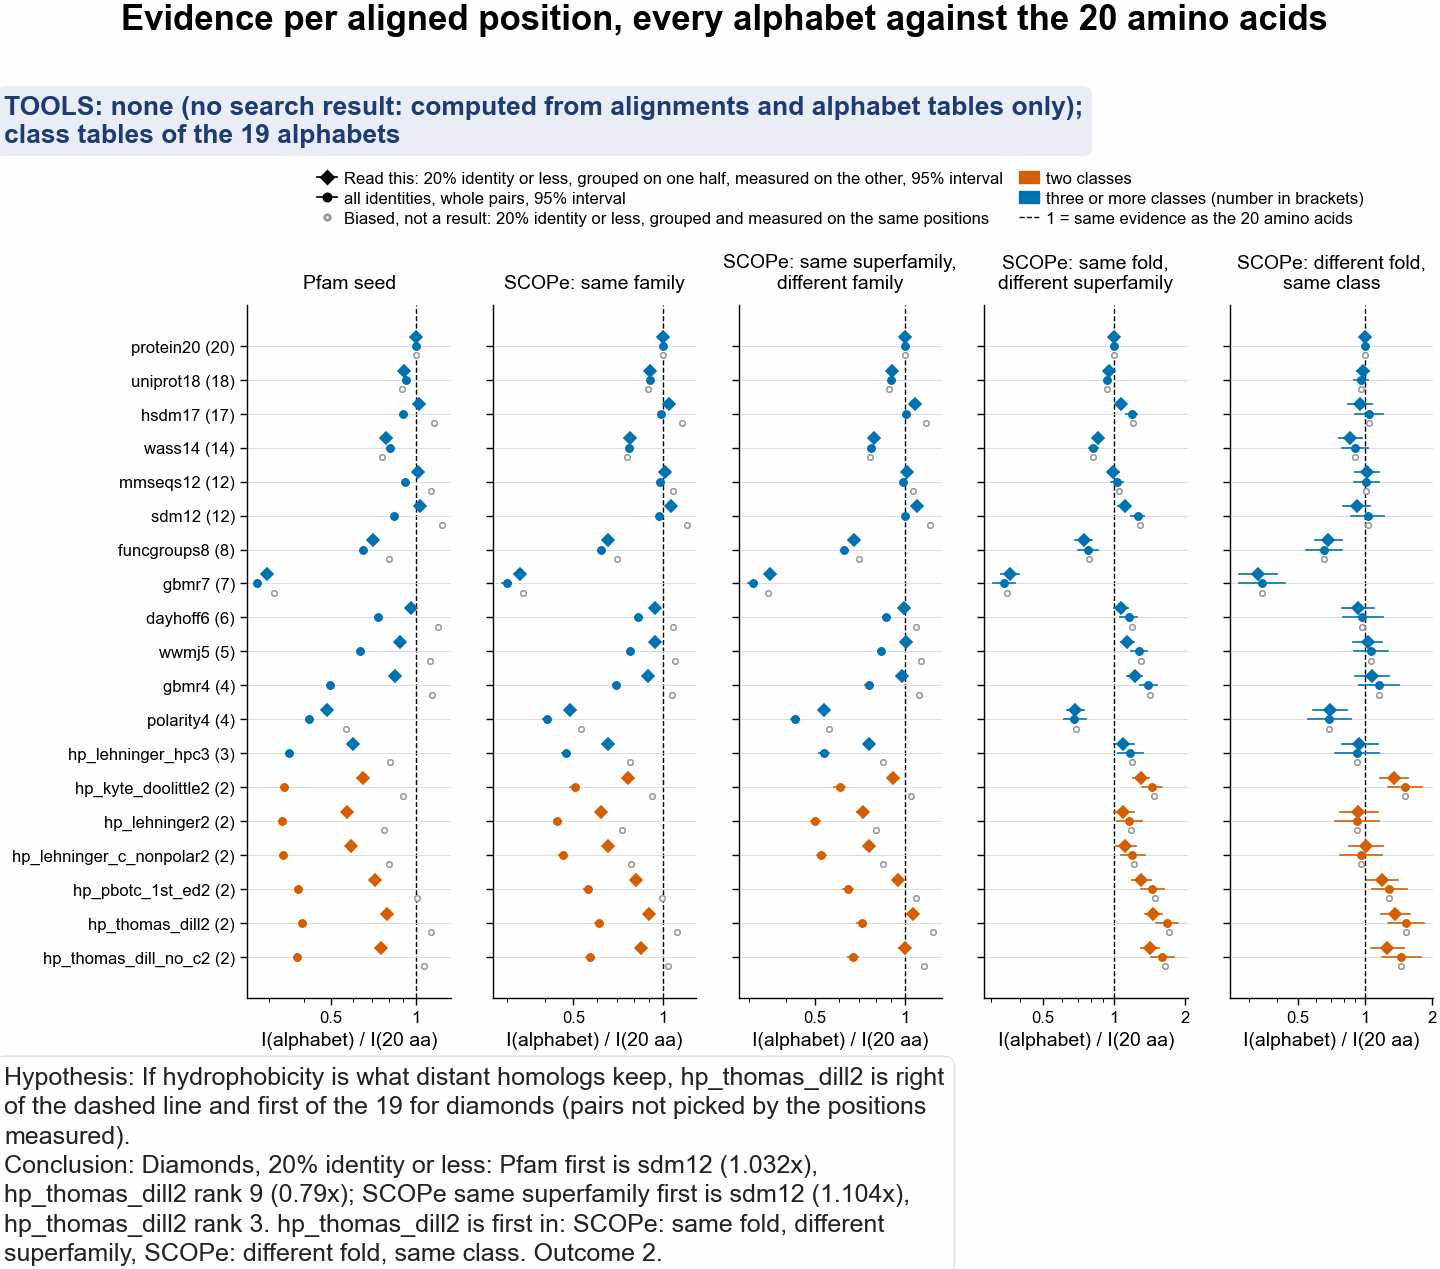

In [6]:
pf.use_style()
panels = list(GROUPS)
# the legend gets its own row above the panels, so the figure header cannot cover it
fig = plt.figure(figsize=(pf.TWO_COLUMN_MM * pf.MM, 115 * pf.MM), layout="constrained")
gs = fig.add_gridspec(2, len(panels), height_ratios=[1, 9])
legend_ax = fig.add_subplot(gs[0, :])
legend_ax.axis("off")
axs = [fig.add_subplot(gs[1, 0])]
axs += [fig.add_subplot(gs[1, i], sharey=axs[0]) for i in range(1, len(panels))]
for ax in axs[1:]:
    ax.tick_params(labelleft=False)
COL = {True: pf.OKABE_ITO["vermillion"], False: pf.OKABE_ITO["blue"]}
BIASED = pf.GREY
MARK = (
    {  # one shape per way of choosing the pairs; the fair test sits on top of each row
        "low_half": dict(marker="D", mfc=None, dy=-0.27, ms=3.2),
        "all": dict(marker="o", mfc=None, dy=0.0, ms=2.6),
        "low_same": dict(
            marker="o", mfc="white", dy=0.27, ms=2.0
        ),  # biased: grey, not read
    }
)
y = np.arange(len(ALPHABETS))
for ax, g in zip(axs, panels):
    gname = g.replace("\n", " ")
    ax.axvline(1, color="black", lw=0.5, ls="--", zorder=0)
    for yy in y:
        ax.axhline(yy, color="#d9d9d9", lw=0.3, zorder=0)
    for k, mk in MARK.items():
        t = res.filter((pl.col("group") == gname) & (pl.col("mode") == k))
        t = t.with_columns(
            pl.col("alphabet")
            .replace_strict({a: i for i, a in enumerate(ALPHABETS)})
            .alias("y")
        )
        for r in t.iter_rows(named=True):
            c = BIASED if k == "low_same" else COL[r["classes"] == 2]
            if k != "low_same":
                ax.plot([r["lo"], r["hi"]], [r["y"] + mk["dy"]] * 2, color=c, lw=0.6)
            ax.plot(
                r["ratio_to_20aa"],
                r["y"] + mk["dy"],
                marker=mk["marker"],
                ms=mk["ms"],
                ls="none",
                mec=c,
                mfc=mk["mfc"] or c,
                mew=0.6,
            )
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    lo = res.filter(pl.col("group") == gname)["lo"].min()
    hi = res.filter(pl.col("group") == gname)["hi"].max()
    ax.set_xticks([t for t in (0.1, 0.2, 0.5, 1, 2, 4) if lo * 0.8 <= t <= hi * 1.25])
    ax.set_title(g)
    ax.set_xlabel("I(alphabet) / I(20 aa)")
axs[0].set_yticks(y, [f"{a} ({N_CLASSES[a]})" for a in ALPHABETS])
axs[0].invert_yaxis()
handles = [
    Line2D(
        [],
        [],
        marker="D",
        ms=3.2,
        color="black",
        ls="-",
        lw=0.6,
        label="Read this: " + MODES["low_half"] + ", 95% interval",
    ),
    Line2D(
        [],
        [],
        marker="o",
        ms=2.6,
        color="black",
        ls="-",
        lw=0.6,
        label=MODES["all"] + ", 95% interval",
    ),
    Line2D(
        [],
        [],
        marker="o",
        ms=2.0,
        mfc="white",
        mec=BIASED,
        ls="none",
        label="Biased, not a result: " + MODES["low_same"],
    ),
    Patch(color=COL[True], label="two classes"),
    Patch(color=COL[False], label="three or more classes (number in brackets)"),
    Line2D(
        [],
        [],
        color="black",
        ls="--",
        lw=0.5,
        label="1 = same evidence as the 20 amino acids",
    ),
]
legend_ax.legend(handles=handles, loc="center", ncol=2, frameon=False)
pf.save(
    fig,
    FIG / "291_evidence_ratio_19_alphabets_vs_20aa_pfam_seed_scope40_print",
    formats=("pdf", "png"),
)

lh = rule.filter(pl.col("pairs_used") == MODES["low_half"])
pfr = lh.filter(pl.col("group") == "Pfam seed").row(0, named=True)
ssf = lh.filter(pl.col("group") == "SCOPe: same superfamily, different family").row(
    0, named=True
)
hp_first = lh.filter(pl.col("first") == HP)["group"].to_list()
stamp(
    fig,
    FIG / "291_evidence_ratio_19_alphabets_vs_20aa_pfam_seed_scope40.png",
    tools=TOOLS,
    title="Evidence per aligned position, every alphabet against the 20 amino acids",
    hypothesis=(
        f"If hydrophobicity is what distant homologs keep, {HP} is right of the dashed line and "
        "first of the 19 for diamonds (pairs not picked by the positions measured)."
    ),
    conclusion=(
        f"Diamonds, 20% identity or less: Pfam first is {pfr['first']} ({pfr['first_ratio']}x), "
        f"{HP} rank {pfr['hp_rank']} ({pfr['hp_ratio']}x); SCOPe same superfamily first is "
        f"{ssf['first']} ({ssf['first_ratio']}x), {HP} rank {ssf['hp_rank']}. "
        f"{HP} is first in: {', '.join(hp_first) or 'no group'}. Outcome {OUTCOME['low_half']}."
    ),
)

**Why the open circles and the diamonds differ.** Olga asked on PR 99 (2026-10-15) why
`dayhoff6`, `wwmj5` and `gbmr4` look better than the 20 amino acids in the figure. Their grey
open circles (the biased view) are right of the line in the Pfam panel; their diamonds are left
of it. The table below
gives, for Pfam seed pairs at 20% identity or less, each alphabet's I in both views.

A pair goes in the 20% or less group when few of its positions hold the same residue. In the
biased view those same positions are then measured, so the 20 amino acid I is low partly
because the pairs were chosen for being low on it. A merged alphabet also counts swaps inside
one of its classes (for `dayhoff6`, I for V, D for E), which the choice by identity did not look
at, so its I is pulled down less. Measured on the other half, the 20 amino acid I rises more
than any merged alphabet's, and the ratio falls.

In [7]:
# Pfam seed, 20% identity or less: I in the biased view and on the other half, every alphabet
both = (
    res.filter(pl.col("group") == "Pfam seed")
    .pivot(on="mode", index=["alphabet", "classes"], values=["I_bits", "ratio_to_20aa"])
    .select(
        "alphabet",
        "classes",
        pl.col("I_bits_low_same").round(4).alias("I_same_positions"),
        pl.col("I_bits_low_half").round(4).alias("I_other_half"),
        (pl.col("I_bits_low_half") / pl.col("I_bits_low_same"))
        .round(2)
        .alias("other_half_over_same"),
        pl.col("ratio_to_20aa_low_same").round(3).alias("ratio_same_positions"),
        pl.col("ratio_to_20aa_low_half").round(3).alias("ratio_other_half"),
    )
    .sort("ratio_other_half", descending=True)
)
print(
    "Pfam seed pairs, 20% identity or less. I in bits per aligned position; ratio = I / I(20 aa)."
)
print(both)

Pfam seed pairs, 20% identity or less. I in bits per aligned position; ratio = I / I(20 aa).
shape: (19, 7)
┌──────────────────────────┬─────────┬──────────────────┬──────────────┬──────────────────────┬──────────────────────┬──────────────────┐
│ alphabet                 ┆ classes ┆ I_same_positions ┆ I_other_half ┆ other_half_over_same ┆ ratio_same_positions ┆ ratio_other_half │
│ ---                      ┆ ---     ┆ ---              ┆ ---          ┆ ---                  ┆ ---                  ┆ ---              │
│ str                      ┆ i64     ┆ f64              ┆ f64          ┆ f64                  ┆ f64                  ┆ f64              │
╞══════════════════════════╪═════════╪══════════════════╪══════════════╪══════════════════════╪══════════════════════╪══════════════════╡
│ sdm12                    ┆ 12      ┆ 0.1122           ┆ 0.1687       ┆ 1.5                  ┆ 1.236                ┆ 1.032            │
│ hsdm17                   ┆ 17      ┆ 0.1056           ┆ 0.1672

## 3. Pfam seed pairs by identity bin, every alphabet

Section 2 used one low-identity group. Here every Pfam identity bin is shown, as the ratio
I(alphabet) / I(20 aa), in the two ways of grouping. The bins are by the 20 amino acid identity
of the half not measured (left) or of the whole pair (right). The left panel is the one without
the picking effect; the right panel is shown only to explain notebook 273's 1.13.

How to read it: read the left panel; the right one is faded because it is biased. Each cell is
one alphabet in one identity bin. Teal: more evidence per position
than the 20 amino acids. Brown: less. White: within 10% of them (0.90 to 1.11). The colour has
9 steps; the number in the cell is the exact ratio.


Pfam seed, I(alphabet) / I(20 aa), ratio_same_positions
shape: (19, 6)
┌──────────────────────────┬───────┬─────────┬─────────┬─────────┬───────┐
│ alphabet                 ┆ <=20% ┆ >20-30% ┆ >30-40% ┆ >40-60% ┆ >60%  │
│ ---                      ┆ ---   ┆ ---     ┆ ---     ┆ ---     ┆ ---   │
│ str                      ┆ f64   ┆ f64     ┆ f64     ┆ f64     ┆ f64   │
╞══════════════════════════╪═══════╪═════════╪═════════╪═════════╪═══════╡
│ protein20                ┆ 1.0   ┆ 1.0     ┆ 1.0     ┆ 1.0     ┆ 1.0   │
│ uniprot18                ┆ 0.89  ┆ 0.901   ┆ 0.911   ┆ 0.92    ┆ 0.929 │
│ hsdm17                   ┆ 1.163 ┆ 0.99    ┆ 0.929   ┆ 0.889   ┆ 0.861 │
│ wass14                   ┆ 0.755 ┆ 0.77    ┆ 0.787   ┆ 0.808   ┆ 0.835 │
│ mmseqs12                 ┆ 1.133 ┆ 1.004   ┆ 0.955   ┆ 0.918   ┆ 0.861 │
│ sdm12                    ┆ 1.236 ┆ 0.986   ┆ 0.893   ┆ 0.824   ┆ 0.758 │
│ funcgroups8              ┆ 0.802 ┆ 0.688   ┆ 0.655   ┆ 0.643   ┆ 0.635 │
│ gbmr7                    ┆

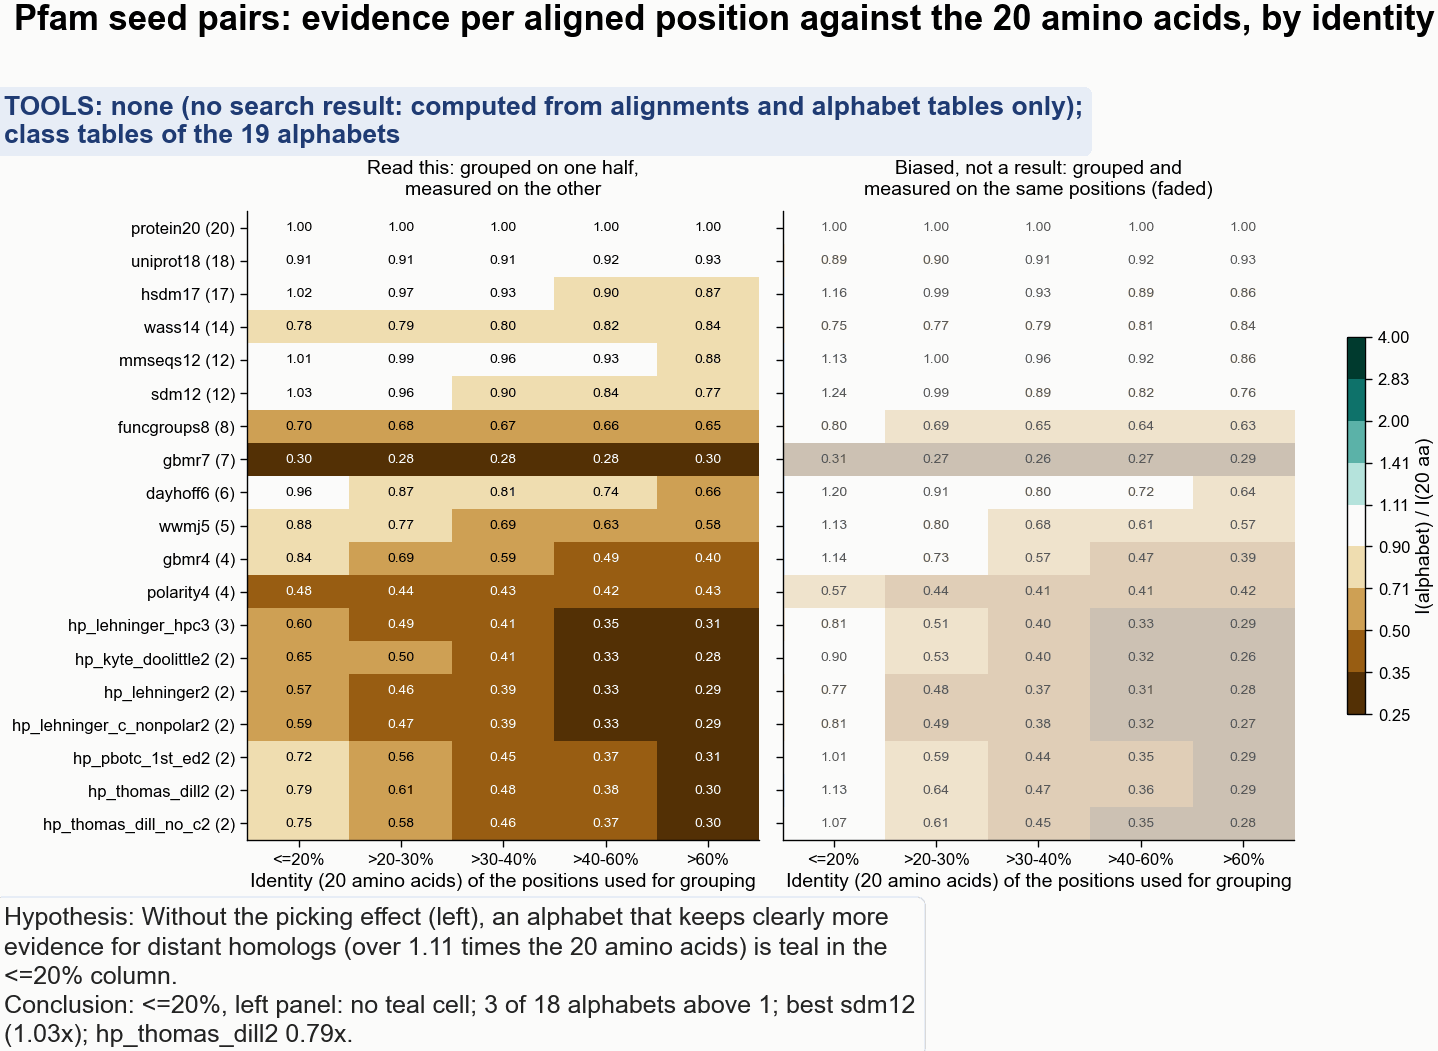

In [8]:
EDGES = [0.0, 0.20, 0.30, 0.40, 0.60, 1.0]
BIN_LABELS = ["<=20%", ">20-30%", ">30-40%", ">40-60%", ">60%"]


def in_bin(x, lo, hi):
    return (x <= hi) if lo == 0 else ((x > lo) & (x <= hi))


rows = []
for lo, hi, lab in zip(EDGES[:-1], EDGES[1:], BIN_LABELS):
    m = in_bin(pf_agree[I_P20], lo, hi)
    v = pf_I[:, m]
    v = v[:, ~np.isnan(v).any(0)]
    same = v.mean(1) / v[I_P20].mean()
    vals = []
    for grp, meas in ((0, 1), (1, 0)):
        mm = in_bin(pf_ah[I_P20][:, grp], lo, hi)
        vals.append(pf_Ih[:, mm, meas])
    h = np.concatenate(vals, 1)
    h = h[:, ~np.isnan(h).any(0)]
    half = h.mean(1) / h[I_P20].mean()
    for i, a in enumerate(ALPHABETS):
        rows.append(
            dict(
                alphabet=a,
                identity=lab,
                pairs=v.shape[1],
                pair_halves=h.shape[1],
                ratio_same_positions=same[i],
                ratio_other_half=half[i],
            )
        )
bins = pl.DataFrame(rows)
for col in ("ratio_same_positions", "ratio_other_half"):
    print(f"\nPfam seed, I(alphabet) / I(20 aa), {col}")
    print(
        bins.pivot(on="identity", index="alphabet", values=col).with_columns(
            pl.col(pl.Float64).round(3)
        )
    )
print(bins.filter(pl.col("alphabet") == P20).select("identity", "pairs", "pair_halves"))

pf.use_style()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
# 9 colour steps, symmetric around 1 on a log scale: a stepped scale survives the repo's
# 256-colour PNG rule, which shifted cells of a smooth scale to the wrong colour
STEPS = np.array([-2, -1.5, -1, -0.5, -0.15, 0.15, 0.5, 1, 1.5, 2])  # log2 of the ratio
cmap = plt.get_cmap("BrBG", len(STEPS) - 1)
norm = mpl.colors.BoundaryNorm(STEPS, cmap.N)
for ax, col, title in zip(
    axs,
    ("ratio_other_half", "ratio_same_positions"),
    (
        "Read this: grouped on one half,\nmeasured on the other",
        "Biased, not a result: grouped and\nmeasured on the same positions (faded)",
    ),
):
    fair = col == "ratio_other_half"
    M = np.array(
        [
            [
                bins.filter((pl.col("alphabet") == a) & (pl.col("identity") == b))[col][
                    0
                ]
                for b in BIN_LABELS
            ]
            for a in ALPHABETS
        ]
    )
    # the biased panel is faded so the eye goes to the fair test first
    shown = ax.imshow(
        np.log2(M).clip(-2, 2),
        cmap=cmap,
        norm=norm,
        aspect="auto",
        alpha=1 if fair else 0.3,
    )
    if fair:
        im = shown  # the colour bar is drawn from the unfaded panel
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ink = (
                ("white" if abs(np.log2(M[i, j])) > 1 else "black")
                if fair
                else "#555555"
            )
            ax.text(
                j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=5, color=ink
            )
    ax.set_xticks(range(len(BIN_LABELS)), BIN_LABELS)
    ax.set_xlabel("Identity (20 amino acids) of the positions used for grouping")
    ax.set_title(title)
axs[0].set_yticks(range(len(ALPHABETS)), [f"{a} ({N_CLASSES[a]})" for a in ALPHABETS])
cb = fig.colorbar(im, ax=axs, shrink=0.6, ticks=STEPS)
cb.ax.set_yticklabels([f"{2**v:.2f}" for v in STEPS])
cb.set_label("I(alphabet) / I(20 aa)")
pf.save(
    fig,
    FIG / "291_evidence_ratio_by_identity_19_alphabets_pfam_seed_print",
    formats=("pdf", "png"),
)

low = bins.filter(pl.col("identity") == "<=20%")
n_above = low.filter(
    (pl.col("ratio_other_half") > 1) & (pl.col("alphabet") != P20)
).height
stamp(
    fig,
    FIG / "291_evidence_ratio_by_identity_19_alphabets_pfam_seed.png",
    tools=TOOLS,
    title="Pfam seed pairs: evidence per aligned position against the 20 amino acids, by identity",
    hypothesis=(
        "Without the picking effect (left), an alphabet that keeps clearly more evidence for "
        "distant homologs (over 1.11 times the 20 amino acids) is teal in the <=20% column."
    ),
    conclusion=(
        f"<=20%, left panel: no teal cell; {n_above} of {len(ALPHABETS) - 1} alphabets above 1; best "
        f"{low.sort('ratio_other_half', descending=True)['alphabet'][0]} "
        f"({low['ratio_other_half'].max():.2f}x); {HP} "
        f"{low.filter(pl.col('alphabet') == HP)['ratio_other_half'][0]:.2f}x."
    ),
)

## 4. Summary and conclusions

**Question.** Notebook 273 found that `hp_thomas_dill2` keeps more evidence per aligned position
than the 20 amino acids in Pfam seed pairs at 20% identity or less, and that the lead goes away
when the pairs are not picked by the positions measured. Does this hold for every two-class
alphabet, and how do all 19 alphabets compare?

**Answer.** Outcome 2 of the decision rule. For distant homologs, a few alphabets keep slightly
more evidence per aligned position than the 20 amino acids: `sdm12`, `hsdm17` and, in Pfam,
`mmseqs12`, by 1 to 10%. No two-class alphabet does in Pfam, and only `hp_thomas_dill2` does
among SCOPe same-superfamily pairs. The two-class alphabets lead only for SCOPe pairs that
SCOPe does not call homologs.

1. Pfam seed pairs at 20% identity or less, grouped on one half and measured on the other
   (37,573 pair-halves from 10,921 families): 3 of the 18 alphabets are above the 20 amino
   acids. `sdm12` 1.032 times (95% interval 1.027 to 1.038), `hsdm17` 1.023, `mmseqs12` 1.014.
   All six two-class alphabets are below, from 0.57 (`hp_lehninger2`) to 0.79
   (`hp_thomas_dill2`, rank 9 of 19).
2. The biased view, grouped and measured on the same positions, puts 9 of the 18 above 1 in
   the same Pfam group: `sdm12` 1.24, `dayhoff6` 1.20, `hsdm17` 1.16, `gbmr4` 1.14,
   `hp_thomas_dill2` 1.13 and four more. Picking pairs by their 20 amino acid identity lifts
   every alphabet that merges letters, so notebook 273's 1.13 says nothing specific about H/P.
   On the other half, the 20 amino acid I rises 1.80 times (0.0908 to 0.1634 bits), `dayhoff6`
   1.43 times, `wwmj5` 1.40 and `gbmr4` 1.33, so all three end below the 20 amino acids: 0.958,
   0.879 and 0.841.
3. SCOPe homologs at 20% identity or less, grouped on one half: in same-family pairs (11,033
   pair-halves, 468 folds), `sdm12` 1.063 and `hsdm17` 1.048 are above 1, and every two-class
   alphabet is below (`hp_thomas_dill2` 0.90). In same-superfamily, different-family pairs
   (17,303 pair-halves, 451 folds), four are above 1: `sdm12` 1.104, `hsdm17` 1.081,
   `hp_thomas_dill2` 1.065 (1.027 to 1.105) and `mmseqs12` 1.020. `sdm12` is first in 98.6% of
   resamples. The other five two-class alphabets are at or below 1 (0.72 to 1.00).
4. SCOPe pairs that are not homologs by SCOPe's definition, at 20% identity or less, grouped on
   one half: same fold, different superfamily (2,345 pair-halves, 112 folds), `hp_thomas_dill2`
   is first in every resample at 1.47 times, and 5 of the 9 alphabets above 1 have two classes.
   Different fold, same class (368 pair-halves, 138 folds): the 4 alphabets above 1 all have two
   classes; `hp_thomas_dill2` is first in 61% of resamples and `hp_kyte_doolittle2` in 37%.
5. Among the two-class alphabets the order barely changes between groups: `hp_thomas_dill2`,
   then `hp_thomas_dill_no_c2` and `hp_pbotc_1st_ed2`, then `hp_kyte_doolittle2`, then the two
   two-class Lehninger alphabets, which put glycine and proline in the hydrophobic class.
   (`hp_thomas_dill2` and `hp_pbotc_1st_ed2` differ only in proline.)
   This fits notebook 273 section 4b: of all 167,960 splits into 9 and 11 amino acids,
   ACFILMVWY keeps the most evidence in every SCOPe group.
6. Over all identities, without picking by identity, the 20 amino acids keep the most evidence
   in Pfam seed pairs and SCOPe same-family pairs. In SCOPe same-superfamily pairs only `hsdm17`
   beats them (1.012, 1.003 to 1.021). Section 3 shows the same in every Pfam
   identity bin above 20%: no alphabet is above 1 once pairs are grouped on the other half.

**What this means for the paper.** Do not write that H/P keeps more evidence per aligned
position than the 20 amino acids between distant homologs. With the correct alignment given,
the alphabets that keep more are `sdm12` and `hsdm17`, and only by 2 to 10%. H/P's clear lead
(1.4 to 1.7 times) is between structure-aligned domains that SCOPe puts in different
superfamilies or folds. A structural superposition places buried positions on buried positions,
so this lead may come from packing rather than from a common ancestor (notebook 273, item 6).

**Limits.**

* All of this is per aligned position, for a method given the correct alignment. An exact k-mer
  search sees less: notebook 230 found an H/P 26-mer shared by 1.7% of 20-30% pairs.
* The intervals resample Pfam families or the query domain's SCOPe fold only.
* Neighbouring positions are not independent, so grouping on even positions and measuring on
  odd ones removes most of the picking effect, not necessarily all of it.
* The whole-pair numbers for all 19 alphabets had been seen in notebook 230's table before the
  decision rule was written.